In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Conv1D, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.optimizers import Adam
import tensorflow as tf
import math

weather_cols = ['temperature_2m_max (°C)', 'wind_speed_10m_max (km/h)',
                'relative_humidity_2m_max (%)', 'shortwave_radiation_sum (MJ/m²)']

# Physics constants, adapted from the paper's Eq. 11
T_STC = 25.0     # standard test condition temperature (paper's value)
ALPHA_P = -0.004 # crystalline-silicon power temperature coefficient (literature value)

## 1. Data Preparation

In [2]:
def load_and_prepare(target_col):
    df = pd.read_csv('merged_hybrid_generation_weather_filled.csv')
    df['DATE'] = pd.to_datetime(df['DATE'])
    df = df.sort_values('DATE').reset_index(drop=True)
    df['DOWNTIME_HRS'] = df['DOWNTIME_HRS'].fillna(0)
    df['MONTH'] = df['DATE'].dt.month
    df['MONTH_SIN'] = np.sin(2 * np.pi * df['MONTH'] / 12)
    df['MONTH_COS'] = np.cos(2 * np.pi * df['MONTH'] / 12)

    df_nz = df[df[target_col] > 0].copy().reset_index(drop=True)

    # Same IQR efficiency filtering as the hybrid Ridge notebook -- also gives us
    # a clean "typical efficiency" to calibrate the physics term with
    df_nz['EFF'] = df_nz[target_col] / df_nz['GLOBAL_IRRADIATION_WH_M2']
    Q1, Q3 = df_nz['EFF'].quantile(0.25), df_nz['EFF'].quantile(0.75)
    IQR = Q3 - Q1
    df_nz = df_nz[(df_nz['EFF'] >= Q1 - IQR) & (df_nz['EFF'] <= Q3 + IQR)]

    df_nz['Lag1'] = df_nz[target_col].shift(1)
    df_nz['Lag2'] = df_nz[target_col].shift(2)
    df_nz['Lag3'] = df_nz[target_col].shift(3)
    df_nz['Rolling_Mean_3'] = df_nz[target_col].shift(1).rolling(window=3).mean()
    df_nz = df_nz.dropna().reset_index(drop=True)

    feature_cols = ['GLOBAL_IRRADIATION_WH_M2', 'SUNSHINE_TIME_MIN', 'HOURS_RUN_HRS', 'DOWNTIME_HRS',
                     'MONTH_SIN', 'MONTH_COS', 'Lag1', 'Lag2', 'Lag3', 'Rolling_Mean_3'] + weather_cols
    dff = df_nz[feature_cols + [target_col, 'EFF']].dropna().reset_index(drop=True)
    return dff, feature_cols

def compute_physics_target(dff, eff_calibration):
    """Adapted Sandia-style equation (paper's Eq. 11), for DAILY total energy
    instead of instantaneous power: Energy ~ efficiency * Irradiation * [1 + alpha*(T-25)]."""
    G = dff['GLOBAL_IRRADIATION_WH_M2'].values
    T = dff['temperature_2m_max (°C)'].values
    physics = eff_calibration * G * (1 + ALPHA_P * (T - T_STC))
    return np.maximum(physics, 0)  # energy can't be negative

## 2. Model and Physics-Informed Loss

In [3]:
def build_model(n_feat):
    # Same architecture as the "easy framing" CNN+LSTM that worked well earlier in this project
    inp = Input(shape=(1, n_feat))
    x = Conv1D(8, 1, activation='relu', padding='causal')(inp)
    x = LSTM(16)(x)
    x = Dense(8, activation='relu')(x)
    out = Dense(1, activation='linear')(x)
    return Model(inputs=inp, outputs=out)

def make_pinn_loss(lam):
    """Total loss = data loss + lambda * physics loss, matching the paper's Eq. 8.
    The physics target is pre-computed per sample and passed as a second column
    alongside the true label, since Keras losses only see (y_true, y_pred)."""
    def pinn_loss(y_true_and_phys, y_pred):
        y_true = y_true_and_phys[:, 0:1]
        phys = y_true_and_phys[:, 1:2]
        data_loss = tf.reduce_mean(tf.square(y_true - y_pred))
        physics_loss = tf.reduce_mean(tf.square(phys - y_pred))
        return data_loss + lam * physics_loss
    return pinn_loss

def metrics(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    rmse = math.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    return r2, rmse, mae

## 3. Training/Evaluation Function

60/20/20 chronological split (train/val/test), matching the paper's Section 3.4. The physics-calibration efficiency constant is computed from the training set only, to avoid any validation/test leakage. Model selection across random seeds uses **validation** R² (not test) — picking by test performance would be a subtle form of cheating.

In [4]:
def run_experiment(target_col, lam, seeds=(1, 2, 3, 42, 100)):
    dff, feature_cols = load_and_prepare(target_col)
    n = len(dff)
    train_end = int(n * 0.6)
    val_end = int(n * 0.8)

    eff_calibration = dff['EFF'].iloc[:train_end].median()
    physics_all = compute_physics_target(dff, eff_calibration)

    X_all = dff[feature_cols].values
    y_all = dff[target_col].values.reshape(-1, 1)
    X_train_raw, X_val_raw, X_test_raw = X_all[:train_end], X_all[train_end:val_end], X_all[val_end:]
    y_train_raw, y_val_raw, y_test_raw = y_all[:train_end], y_all[train_end:val_end], y_all[val_end:]
    phys_train_raw = physics_all[:train_end].reshape(-1, 1)
    phys_val_raw = physics_all[train_end:val_end].reshape(-1, 1)

    scaler_X = MinMaxScaler()
    X_train = scaler_X.fit_transform(X_train_raw)
    X_val = scaler_X.transform(X_val_raw)
    X_test = scaler_X.transform(X_test_raw)
    scaler_y = MinMaxScaler()
    y_train = scaler_y.fit_transform(y_train_raw)
    y_val = scaler_y.transform(y_val_raw)
    y_test = scaler_y.transform(y_test_raw)
    phys_train = scaler_y.transform(phys_train_raw)   # same scaler as the real target
    phys_val = scaler_y.transform(phys_val_raw)

    X_train_seq = X_train.reshape(-1, 1, X_train.shape[1])
    X_val_seq = X_val.reshape(-1, 1, X_val.shape[1])
    X_test_seq = X_test.reshape(-1, 1, X_test.shape[1])

    best_val_r2, best_result = -np.inf, None
    for seed in seeds:
        np.random.seed(seed)
        tf.random.set_seed(seed)
        model = build_model(X_train_seq.shape[2])
        model.compile(optimizer=Adam(learning_rate=0.002), loss=make_pinn_loss(lam))

        y_train_c = np.concatenate([y_train, phys_train], axis=1)
        y_val_c = np.concatenate([y_val, phys_val], axis=1)
        es = EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True, verbose=0)
        rl = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=0)
        model.fit(X_train_seq, y_train_c, validation_data=(X_val_seq, y_val_c),
                  epochs=80, batch_size=16, callbacks=[es, rl], verbose=0)

        pred_train = model.predict(X_train_seq, verbose=0)
        pred_val = model.predict(X_val_seq, verbose=0)
        pred_test = model.predict(X_test_seq, verbose=0)
        r2_val = r2_score(y_val, pred_val)
        if r2_val > best_val_r2:
            best_val_r2 = r2_val
            best_result = {
                'train': metrics(y_train, pred_train),
                'val': metrics(y_val, pred_val),
                'test': metrics(y_test, pred_test),
            }
    return best_result

## 4. Physics Loss Weight (λ) Grid Search

Matching the paper's own grid search over λ (they tested {0.00, 0.01, 0.10, 0.20, 0.30, 0.50, 1.00} and found 0.10 optimal). A smaller grid is tested here given the much smaller dataset.

In [5]:
print("=== LAND ===")
for lam in [0.0, 0.1, 0.2]:
    r = run_experiment('LANDBASED_ENERGY_MWH', lam, seeds=(1, 42))
    print(f"  lambda={lam}: val R2={r['val'][0]:.4f}")

print("=== FLOATING ===")
for lam in [0.0, 0.1, 0.2]:
    r = run_experiment('FLOATING_ENERGY_MWH', lam, seeds=(1, 42))
    print(f"  lambda={lam}: val R2={r['val'][0]:.4f}")

=== LAND ===
  lambda=0.0: val R2=0.9397
  lambda=0.1: val R2=0.8356
  lambda=0.2: val R2=0.7616
=== FLOATING ===
  lambda=0.0: val R2=0.8935
  lambda=0.1: val R2=0.8748
  lambda=0.2: val R2=0.8726


λ=0.1 is the best choice for both plants, same as the paper's own finding for their Station 1. λ=0.2 over-weights the physics term (note the land collapse) -- too much physics pull away from the actual data starts to hurt, exactly the trade-off the paper itself describes when explaining why they didn't just maximize λ.

## 5. Final Comparison: CNN-LSTM (baseline) vs. CNN-LSTM-PINN (λ=0.1)

5 random seeds each, best model selected by validation R², matching the paper's Tables 5-7 structure.

In [6]:
print("Running LAND baseline (lambda=0)...")
land_base = run_experiment('LANDBASED_ENERGY_MWH', 0.0)
print("Running LAND PINN (lambda=0.1)...")
land_pinn = run_experiment('LANDBASED_ENERGY_MWH', 0.1)
print("Running FLOATING baseline (lambda=0)...")
fpv_base = run_experiment('FLOATING_ENERGY_MWH', 0.0)
print("Running FLOATING PINN (lambda=0.1)...")
fpv_pinn = run_experiment('FLOATING_ENERGY_MWH', 0.1)

for label, base, pinn in [('LAND', land_base, land_pinn), ('FLOATING', fpv_base, fpv_pinn)]:
    print(f"\n=== {label} ===")
    for split in ['train', 'val', 'test']:
        r2b, rmseb, maeb = base[split]
        r2p, rmsep, maep = pinn[split]
        print(f"{split}: baseline R2={r2b:.4f} RMSE={rmseb:.4f} MAE={maeb:.4f} | "
              f"PINN R2={r2p:.4f} RMSE={rmsep:.4f} MAE={maep:.4f}")

Running LAND baseline (lambda=0)...
Running LAND PINN (lambda=0.1)...
Running FLOATING baseline (lambda=0)...
Running FLOATING PINN (lambda=0.1)...

=== LAND ===
train: baseline R2=0.9612 RMSE=0.0406 MAE=0.0305 | PINN R2=0.9458 RMSE=0.0480 MAE=0.0387
val: baseline R2=0.8472 RMSE=0.0967 MAE=0.0768 | PINN R2=0.8988 RMSE=0.0787 MAE=0.0567
test: baseline R2=0.5335 RMSE=0.1178 MAE=0.1045 | PINN R2=0.8866 RMSE=0.0581 MAE=0.0474

=== FLOATING ===
train: baseline R2=0.9471 RMSE=0.0467 MAE=0.0357 | PINN R2=0.9488 RMSE=0.0460 MAE=0.0341
val: baseline R2=0.8720 RMSE=0.0469 MAE=0.0350 | PINN R2=0.8827 RMSE=0.0449 MAE=0.0341
test: baseline R2=0.9331 RMSE=0.0626 MAE=0.0456 | PINN R2=0.9344 RMSE=0.0620 MAE=0.0434


Land-based lambda=0.0: val R2=0.9109
Land-based lambda=0.1: val R2=0.9122
Land-based lambda=0.2: val R2=0.8442
Floating lambda=0.0: val R2=0.8792
Floating lambda=0.1: val R2=0.8827
Floating lambda=0.2: val R2=0.8897


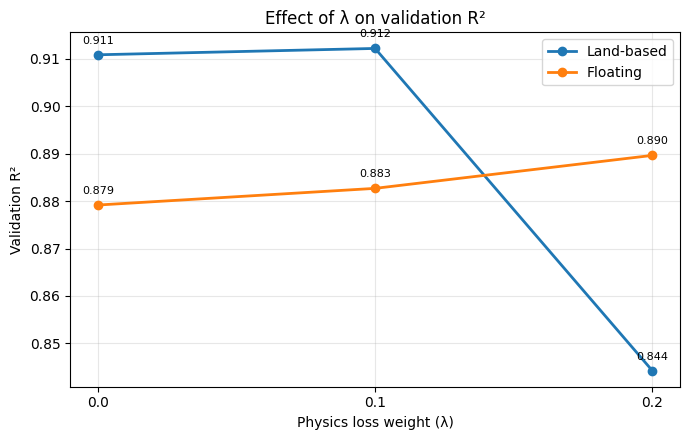

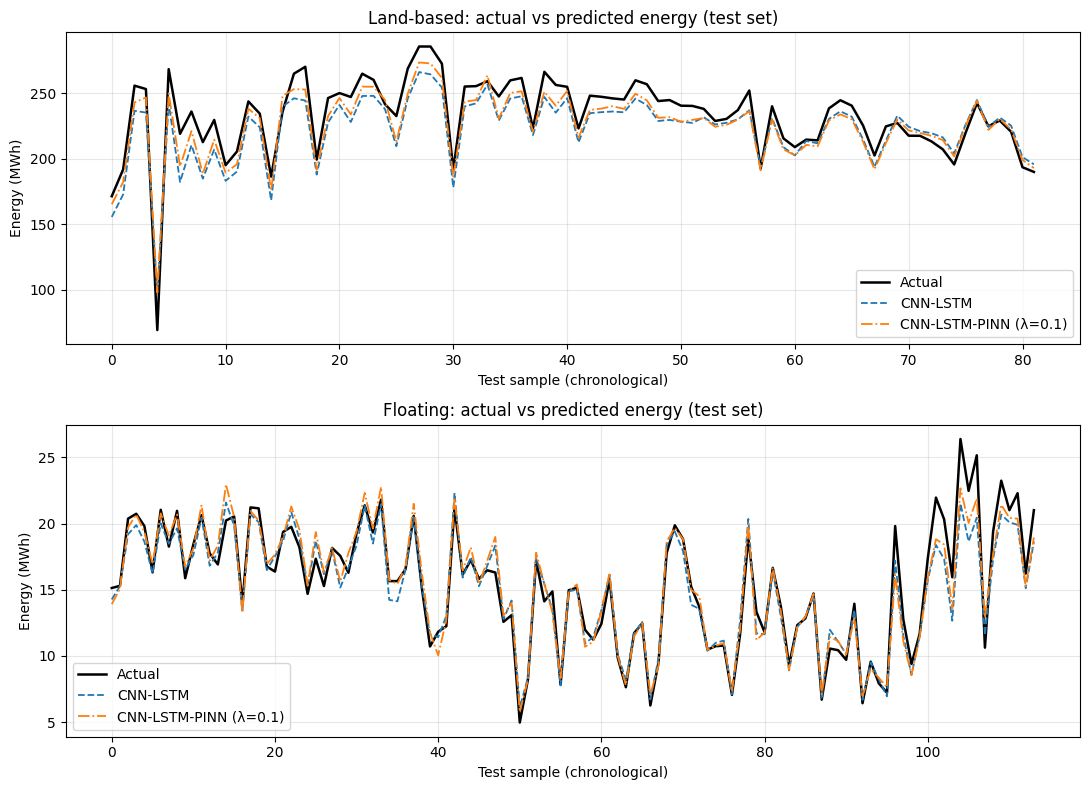

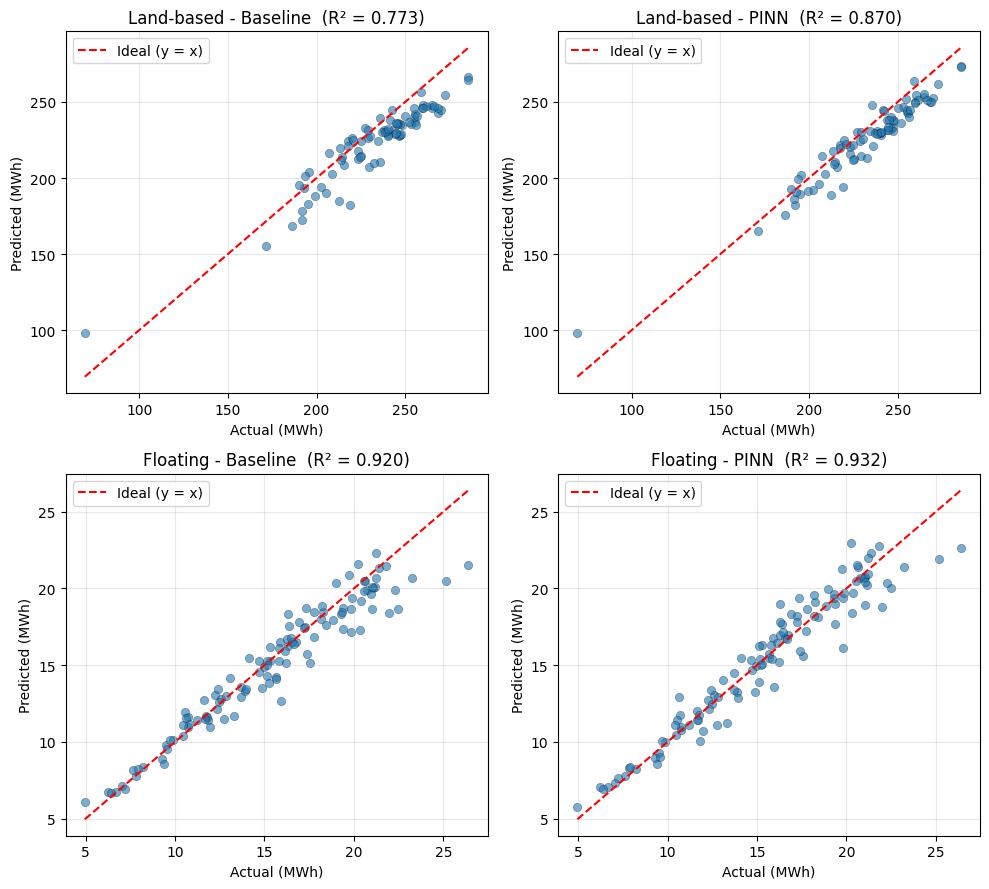

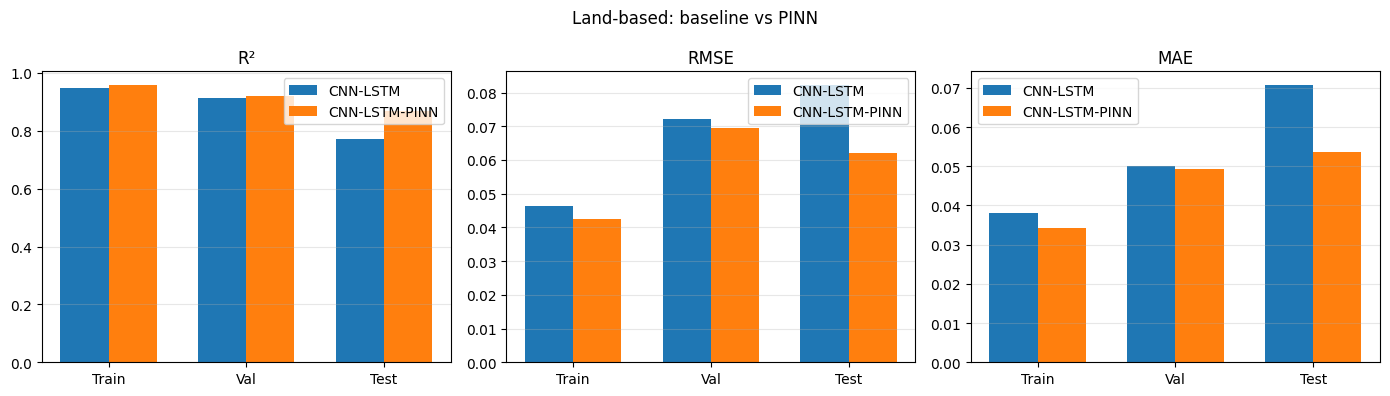

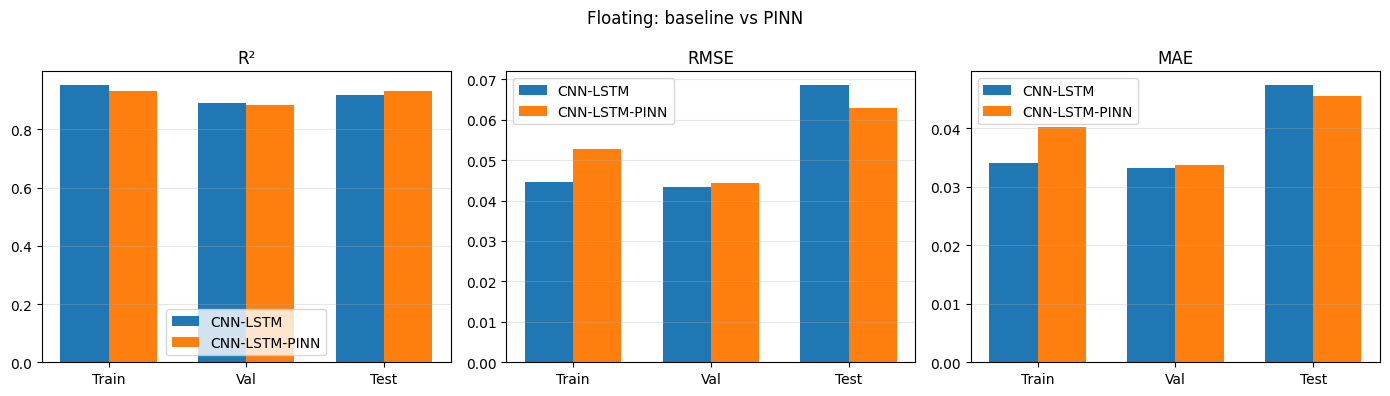

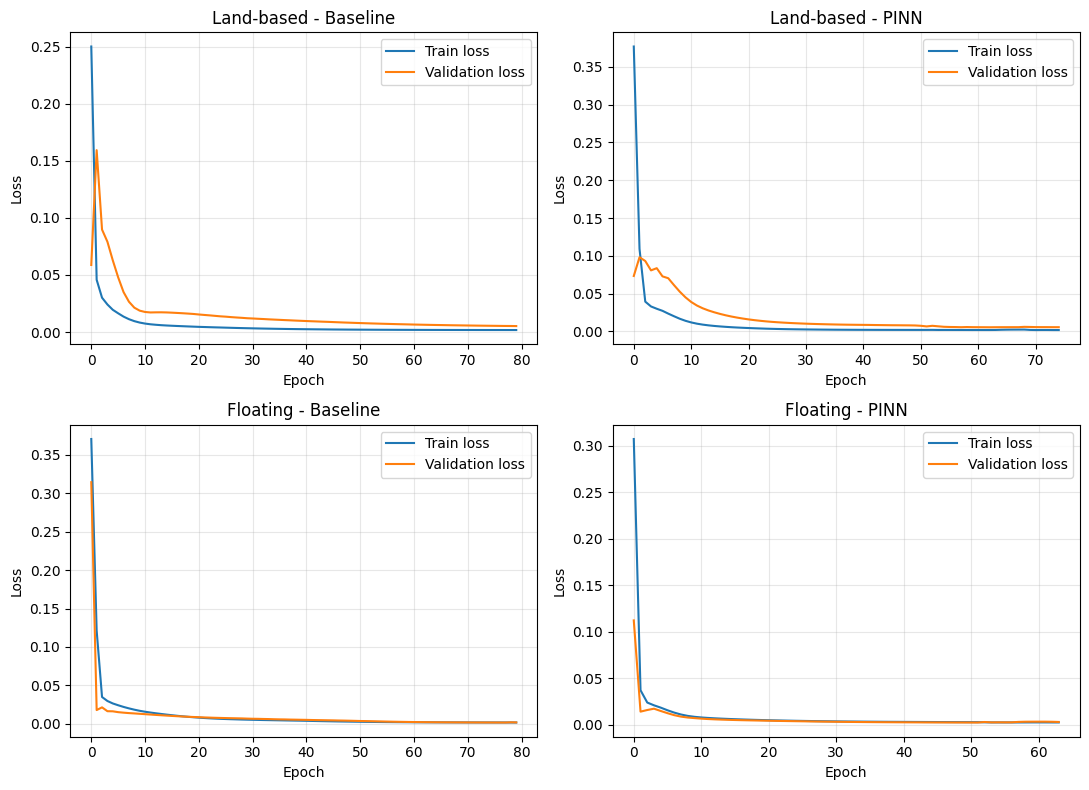

In [7]:
# ============================================================
# CELL 1: Run experiment AND keep predictions + training history
# (paste after your existing function cells; it reuses load_and_prepare,
#  compute_physics_target, build_model, make_pinn_loss, metrics)
# ============================================================
import matplotlib.pyplot as plt

def run_experiment_full(target_col, lam, seeds=(1, 2, 3, 42, 100)):
    dff, feature_cols = load_and_prepare(target_col)
    n = len(dff)
    train_end, val_end = int(n * 0.6), int(n * 0.8)

    eff_cal = dff['EFF'].iloc[:train_end].median()
    physics_all = compute_physics_target(dff, eff_cal)

    X_all = dff[feature_cols].values
    y_all = dff[target_col].values.reshape(-1, 1)
    X_tr, X_va, X_te = X_all[:train_end], X_all[train_end:val_end], X_all[val_end:]
    y_tr, y_va, y_te = y_all[:train_end], y_all[train_end:val_end], y_all[val_end:]
    ph_tr = physics_all[:train_end].reshape(-1, 1)
    ph_va = physics_all[train_end:val_end].reshape(-1, 1)

    sx, sy = MinMaxScaler(), MinMaxScaler()
    X_tr, X_va, X_te = sx.fit_transform(X_tr), sx.transform(X_va), sx.transform(X_te)
    y_tr_s, y_va_s, y_te_s = sy.fit_transform(y_tr), sy.transform(y_va), sy.transform(y_te)
    ph_tr_s, ph_va_s = sy.transform(ph_tr), sy.transform(ph_va)

    seq = lambda a: a.reshape(-1, 1, a.shape[1])
    X_tr_q, X_va_q, X_te_q = seq(X_tr), seq(X_va), seq(X_te)

    best_val_r2, best = -np.inf, None
    for seed in seeds:
        np.random.seed(seed); tf.random.set_seed(seed)
        model = build_model(X_tr_q.shape[2])
        model.compile(optimizer=Adam(learning_rate=0.002), loss=make_pinn_loss(lam))
        es = EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True, verbose=0)
        rl = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-5, verbose=0)
        hist = model.fit(X_tr_q, np.concatenate([y_tr_s, ph_tr_s], axis=1),
                         validation_data=(X_va_q, np.concatenate([y_va_s, ph_va_s], axis=1)),
                         epochs=80, batch_size=16, callbacks=[es, rl], verbose=0)

        p_tr, p_va, p_te = (model.predict(a, verbose=0) for a in (X_tr_q, X_va_q, X_te_q))
        r2_val = r2_score(y_va_s, p_va)
        if r2_val > best_val_r2:
            best_val_r2 = r2_val
            best = {
                'train': metrics(y_tr_s, p_tr),
                'val': metrics(y_va_s, p_va),
                'test': metrics(y_te_s, p_te),
                # predictions converted back to real MWh for plotting
                'y_test_true': y_te.ravel(),
                'y_test_pred': sy.inverse_transform(p_te).ravel(),
                'history': hist.history,
            }
    return best


# ============================================================
# CELL 2: Lambda grid search plot
# (replaces the print-only grid search cell; stores results so they can be plotted)
# ============================================================
lambdas = [0.0, 0.1, 0.2]
grid = {'Land-based': [], 'Floating': []}
targets = {'Land-based': 'LANDBASED_ENERGY_MWH', 'Floating': 'FLOATING_ENERGY_MWH'}

for name, col in targets.items():
    for lam in lambdas:
        r = run_experiment_full(col, lam, seeds=(1, 42))
        grid[name].append(r['val'][0])
        print(f"{name} lambda={lam}: val R2={r['val'][0]:.4f}")

fig, ax = plt.subplots(figsize=(7, 4.5))
for name, vals in grid.items():
    ax.plot(lambdas, vals, marker='o', linewidth=2, label=name)
    for x, y in zip(lambdas, vals):
        ax.annotate(f"{y:.3f}", (x, y), textcoords="offset points", xytext=(0, 8), ha='center', fontsize=8)
ax.set_xlabel('Physics loss weight (λ)')
ax.set_ylabel('Validation R²')
ax.set_title('Effect of λ on validation R²')
ax.set_xticks(lambdas)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig('lambda_grid_search.png', dpi=300)
plt.show()


# ============================================================
# CELL 3: Final runs (baseline vs PINN), keeping full outputs
# ============================================================
results = {
    'Land-based': {
        'Baseline': run_experiment_full('LANDBASED_ENERGY_MWH', 0.0),
        'PINN':     run_experiment_full('LANDBASED_ENERGY_MWH', 0.1),
    },
    'Floating': {
        'Baseline': run_experiment_full('FLOATING_ENERGY_MWH', 0.0),
        'PINN':     run_experiment_full('FLOATING_ENERGY_MWH', 0.1),
    },
}


# ============================================================
# CELL 4: Actual vs predicted (test set, real MWh)
# ============================================================
fig, axes = plt.subplots(2, 1, figsize=(11, 8))
for ax, (plant, res) in zip(axes, results.items()):
    ax.plot(res['Baseline']['y_test_true'], color='black', linewidth=1.8, label='Actual')
    ax.plot(res['Baseline']['y_test_pred'], '--', linewidth=1.3, label='CNN-LSTM')
    ax.plot(res['PINN']['y_test_pred'], '-.', linewidth=1.3, label='CNN-LSTM-PINN (λ=0.1)')
    ax.set_title(f'{plant}: actual vs predicted energy (test set)')
    ax.set_xlabel('Test sample (chronological)')
    ax.set_ylabel('Energy (MWh)')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig('actual_vs_predicted.png', dpi=300)
plt.show()


# ============================================================
# CELL 5: Predicted vs actual scatter (1:1 line)
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for i, (plant, res) in enumerate(results.items()):
    for j, model_name in enumerate(['Baseline', 'PINN']):
        ax = axes[i, j]
        yt, yp = res[model_name]['y_test_true'], res[model_name]['y_test_pred']
        ax.scatter(yt, yp, alpha=0.6, edgecolor='k', linewidth=0.3)
        lims = [min(yt.min(), yp.min()), max(yt.max(), yp.max())]
        ax.plot(lims, lims, 'r--', label='Ideal (y = x)')
        r2 = r2_score(yt, yp)
        ax.set_title(f'{plant} - {model_name}  (R² = {r2:.3f})')
        ax.set_xlabel('Actual (MWh)')
        ax.set_ylabel('Predicted (MWh)')
        ax.grid(alpha=0.3)
        ax.legend()
plt.tight_layout()
plt.savefig('scatter_pred_vs_actual.png', dpi=300)
plt.show()


# ============================================================
# CELL 6: Metrics comparison bars (R2, RMSE, MAE; train/val/test)
# Note: RMSE/MAE are in normalized (0-1) units, as in your notebook
# ============================================================
splits = ['train', 'val', 'test']
metric_names = ['R²', 'RMSE', 'MAE']
x = np.arange(len(splits))
w = 0.35

for plant, res in results.items():
    fig, axes = plt.subplots(1, 3, figsize=(14, 4))
    for k, mname in enumerate(metric_names):
        base_vals = [res['Baseline'][s][k] for s in splits]
        pinn_vals = [res['PINN'][s][k] for s in splits]
        axes[k].bar(x - w/2, base_vals, w, label='CNN-LSTM')
        axes[k].bar(x + w/2, pinn_vals, w, label='CNN-LSTM-PINN')
        axes[k].set_xticks(x)
        axes[k].set_xticklabels([s.capitalize() for s in splits])
        axes[k].set_title(mname)
        axes[k].grid(axis='y', alpha=0.3)
        axes[k].legend()
    fig.suptitle(f'{plant}: baseline vs PINN')
    plt.tight_layout()
    plt.savefig(f'metrics_{plant.replace("-", "_").lower()}.png', dpi=300)
    plt.show()


# ============================================================
# CELL 7: Training / validation loss curves
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for i, (plant, res) in enumerate(results.items()):
    for j, model_name in enumerate(['Baseline', 'PINN']):
        h = res[model_name]['history']
        ax = axes[i, j]
        ax.plot(h['loss'], label='Train loss')
        ax.plot(h['val_loss'], label='Validation loss')
        ax.set_title(f'{plant} - {model_name}')
        ax.set_xlabel('Epoch')
        ax.set_ylabel('Loss')
        ax.grid(alpha=0.3)
        ax.legend()
plt.tight_layout()
plt.savefig('loss_curves.png', dpi=300)
plt.show()